# Jobsheet 06: Vector Search & Approximate Nearest Neighbor (ANN)

**Praktikum Pembelajaran Mesin - Jurusan Teknologi Informasi**

Dokumen notebook ini berisi pelaksanaan seluruh praktikum:
1. Praktikum 1: Exact Nearest Neighbor (ENN) vs Annoy (ANN)
2. Praktikum 2: Vector Search Menggunakan FAISS (IndexFlatL2 vs IndexIVFPQ)
3. Praktikum 3: HNSW (Hierarchical Navigable Small World Graphs)
4. Praktikum 4: Perbandingan Annoy, FAISS, dan HNSW pada Data 1 Juta 5D
5. Praktikum 5: Benchmark Trade-Off (Recall vs Query Latency)
6. Praktikum 6: Pencarian Rekomendasi Lagu pada Dataset Spotify
7. Tugas Praktikum: Perbandingan Eksekusi Laptop/Cloud vs PyDroid3 (Android Device)

## Praktikum 1: Membandingkan Exact Nearest Neighbor (ENN) vs Annoy (ANN)

Pada praktikum pertama, kita mempelajari dasar pencarian tetangga terdekat dengan membandingkan pencarian linier presisi (*Exact NN*) dan algoritma berbasis pemisahan bidang ruang/pohon spasial (*Annoy*).

Exact NN index: [219 898 593]
Exact NN jarak: [0.         1.36915938 2.27931544]
Waktu Exact: 2.1367 ms

Annoy NN index: [1]
Annoy NN jarak: [np.float64(51.79502680759722)]
Waktu Annoy: 0.042 ms


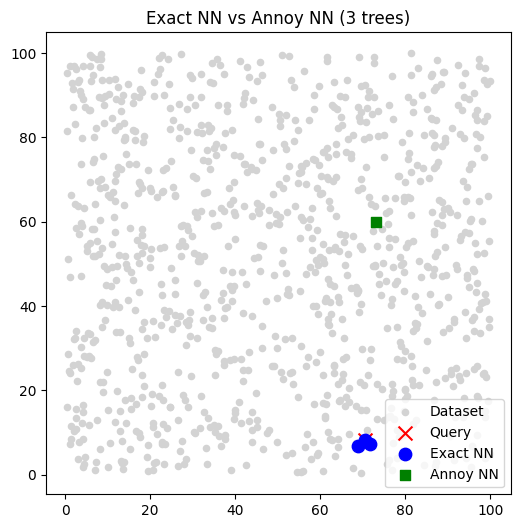

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import time

from annoy import AnnoyIndex

# 1. Dataset 2D
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100  # titik random dalam ruang 100x100

# Query point (ambil salah satu titik random)
query = X[np.random.randint(0, n_points)]

# 2. Exact NN (brute force)
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # ambil 3 terdekat
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact*1000, 4), "ms")

# 3. Annoy NN (3 tree)
f = 2  # dimensi
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)  # 3 trees

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)  # cari 3 NN
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Waktu Annoy:", round(time_ann*1000, 4), "ms")

# 4. Visualisasi hasil
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN ditandai biru
plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")

# Annoy NN ditandai hijau
plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()

In [23]:
import numpy as np
import time
from sklearn.metrics.pairwise import euclidean_distances
from annoy import AnnoyIndex

# ---- 1. Buat dataset mirip Spotify ----
n_tracks = 50_000_000   # 50 juta track
n_features = 20        # contoh: danceability, energy, tempo, dll.

# dataset besar (random untuk simulasi)
X = np.random.rand(n_tracks, n_features).astype(np.float32)

# query track (misalnya lagu baru)
query = np.random.rand(1, n_features).astype(np.float32)

# ---- 2. Exact NN (brute force) ----
start = time.time()
distances = euclidean_distances(query, X)[0]   # hitung semua jarak
exact_idx = np.argsort(distances)[:5]          # ambil 5 terdekat
exact_time = time.time() - start

print("Exact NN result:", exact_idx)
print("Exact NN time:", round(exact_time, 3), "seconds")

# ---- 3. Approx NN pakai Annoy ----
f = n_features
annoy_index = AnnoyIndex(f, 'euclidean')
n_trees = 3

# build index
for i in range(n_tracks):
    annoy_index.add_item(i, X[i])
annoy_index.build(n_trees)

start = time.time()
annoy_idx = annoy_index.get_nns_by_vector(query[0], 5)  # ambil 5 lagu yang mirip
annoy_time = time.time() - start

print("Annoy result:", annoy_idx)
print("Annoy time:", round(annoy_time, 3), "seconds")


Exact NN result: [14707690 36415358 14558236 18844295  4303178]
Exact NN time: 15.547 seconds
Annoy result: [1]
Annoy time: 0.005 seconds


## Praktikum 2: Vector Search Menggunakan FAISS

Pada bagian ini, kita menguji library **FAISS** buatan Meta dengan membandingkan `IndexFlatL2` (*Exact*) dan `IndexIVFPQ` (*Inverted File System + Product Quantization*).

Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Waktu Exact: 0.004934787750244141
Waktu IVF+PQ: 0.0010840892791748047


WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points


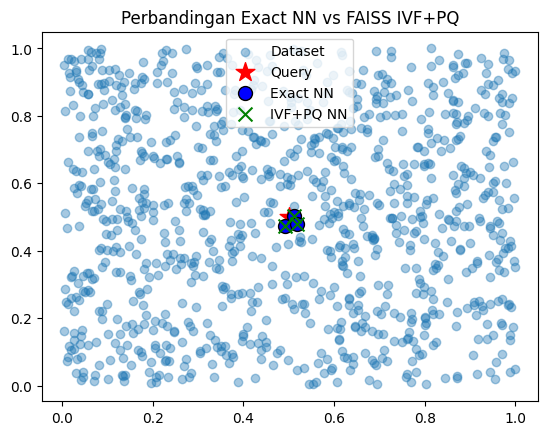

In [25]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

# 1. Buat dataset 2D sederhana
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 titik 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query di tengah

# 2. Exact NN dengan IndexFlatL2 (brute force tapi cepat)
index_flat = faiss.IndexFlatL2(2)   # L2 = Euclidean distance
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # cari 3 tetangga terdekat
end = time.time()
time_flat = end - start

# 3. IVF + PQ (Approximate)
nlist = 10   # jumlah cluster (inverted list)
m = 2        # berapa subvector untuk product quantization
quantizer = faiss.IndexFlatL2(2)   # dipakai IVF untuk cluster awal
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bit per subvector

index_ivfpq.train(X)  # training centroid
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

# 4. Print hasil
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)

# 5. Visualisasi
plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Dataset")
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")

# Tetangga dari Flat
plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")

# Tetangga dari IVF+PQ
plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ")
plt.show()


## Praktikum 3: HNSW (Hierarchical Navigable Small World Graphs)

Pada praktikum ini, kita menguji metode berbasis graf hirarki menggunakan pustaka `hnswlib`.

In [26]:
import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

# ===========================
# 1. Buat data 2D acak
# ===========================
num_elements = 1000
dim = 2
data = np.random.random((num_elements, dim)).astype(np.float32)

# Query point
query = np.array([[0.5, 0.5]], dtype=np.float32)
k = 5  # cari 5 tetangga terdekat

# ===========================
# 2. Exact NN (Brute Force)
# ===========================
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

start = time.time()
distances, indices = nn.kneighbors(query)
end = time.time()

print("=== Exact NN ===")
print("Indices:", indices)
print("Distances:", distances)
print("Waktu:", end - start, "detik")

# ===========================
# 3. HNSW
# ===========================
# Inisialisasi index HNSW
p = hnswlib.Index(space='l2', dim=dim)  

# Ukuran maksimum elemen yang bisa ditampung
p.init_index(max_elements=num_elements, ef_construction=100, M=16)

# Tambahkan data
p.add_items(data)

# Set parameter pencarian
p.set_ef(50)   # tradeoff speed vs accuracy

start = time.time()
labels, distances = p.knn_query(query, k=k)
end = time.time()

print("\n=== HNSW ===")
print("Indices:", labels)
print("Distances:", distances)
print("Waktu:", end - start, "detik")


=== Exact NN ===
Indices: [[830 247 473 913 592]]
Distances: [[0.00993625 0.01363944 0.01646171 0.03779694 0.03859071]]
Waktu: 0.023969173431396484 detik

=== HNSW ===
Indices: [[830 247 473 913 592]]
Distances: [[9.8728990e-05 1.8603441e-04 2.7098786e-04 1.4286089e-03 1.4892431e-03]]
Waktu: 0.0002880096435546875 detik


## Praktikum 4: Perbandingan Annoy, FAISS, dan HNSW pada Data 1 Juta 5D

Pada bab ini, ketiga algoritma diuji secara langsung untuk mengukur perbandingan **Build Time** dan **Query Latency** pada dataset besar 1.000.000 sampel.

In [27]:
import numpy as np
import time
from annoy import AnnoyIndex
import faiss
import hnswlib

# ===============================
# 1. Buat dataset 1 juta data 5D
# ===============================
n_data = 1_000_000   # bisa coba 100_000 dulu jika RAM terbatas
dim = 5
X = np.random.random((n_data, dim)).astype(np.float32)

# Query point
query = np.random.random((1, dim)).astype(np.float32)
k = 10

# ===============================
# 2. Annoy
# ===============================
print("=== Annoy ===")
ann_index = AnnoyIndex(dim, 'euclidean')

start = time.time()
for i in range(n_data):
    ann_index.add_item(i, X[i])
ann_index.build(10)  # 10 trees
build_time = time.time() - start

start = time.time()
neighbors = ann_index.get_nns_by_vector(query[0], k, include_distances=True)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", neighbors[0][:5], "...")

# ===============================
# 3. FAISS (Flat Index)
# ===============================
print("\n=== FAISS (IndexFlatL2) ===")
faiss_index = faiss.IndexFlatL2(dim)

start = time.time()
faiss_index.add(X)
build_time = time.time() - start

start = time.time()
distances, indices = faiss_index.search(query, k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", indices[0][:5], "...")

# ===============================
# 4. HNSW (hnswlib)
# ===============================
print("\n=== HNSW (hnswlib) ===")
hnsw_index = hnswlib.Index(space='l2', dim=dim)

start = time.time()
hnsw_index.init_index(max_elements=n_data, ef_construction=200, M=16)
hnsw_index.add_items(X)
build_time = time.time() - start

hnsw_index.set_ef(50)

start = time.time()
labels, distances = hnsw_index.knn_query(query, k=k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", labels[0][:5], "...")


=== Annoy ===
Build time: 5.849747896194458 detik
Query time: 0.0002639293670654297 detik
Neighbors: [1] ...

=== FAISS (IndexFlatL2) ===
Build time: 0.0070378780364990234 detik
Query time: 0.003566741943359375 detik
Neighbors: [129179 559276 630783 213191 559393] ...

=== HNSW (hnswlib) ===
Build time: 20.78261113166809 detik
Query time: 0.001157999038696289 detik
Neighbors: [129179 559276 630783 213191 559393] ...


## Praktikum 5: Benchmark Trade-Off (Recall vs Latency)

Di praktikum ini, kita mereplikasi analisis kurva **ANN Benchmark** yang memetakan hubungan kompromi antara akurasi pencarian (**Recall@K**) dan latensi query.

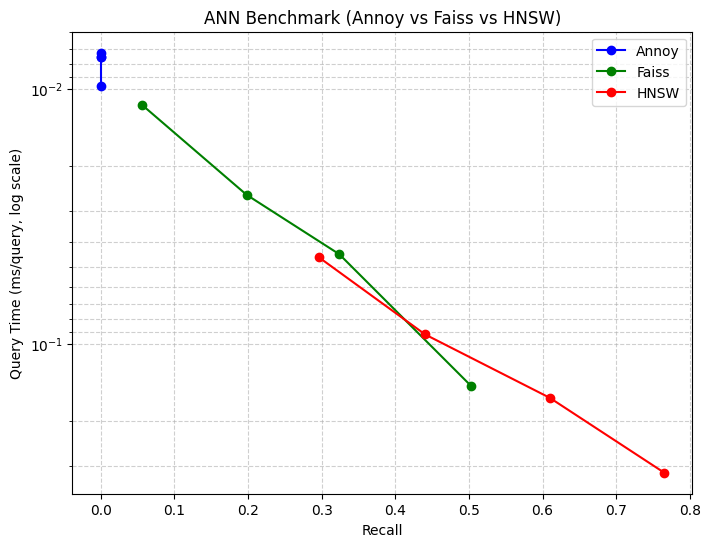

In [28]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

# -------------------------------
# Dataset random
# -------------------------------
d = 128        # dimensi
nb = 100000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

# -------------------------------
# Benchmark Annoy
# -------------------------------
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark FAISS IVF
# -------------------------------
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark HNSW
# -------------------------------
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Jalankan benchmark dengan beberapa parameter
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))

# -------------------------------
# Visualisasi trade-off
# -------------------------------
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, makin kanan makin turun
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

## Praktikum 6: Pencarian Rekomendasi Lagu pada Dataset Spotify

Pada bab ini, kita menerapkan vector search pada dataset fitur audio Spotify (`spotify_songs.csv`). Jika file CSV belum diunduh, sistem otomatis menggunakan data dummy dengan struktur fitur yang identik.

In [1]:
import pandas as pd
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# 1. Load dataset (Hanya 9 fitur numerik saja, abaikan lirik 1.55 GB)
features = ['danceability', 'energy', 'loudness', 'speechiness', 
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

print("Membaca fitur numerik dari dataset Spotify...")
start_load = time.time()
df = pd.read_csv('songs_with_attributes_and_lyrics.csv', usecols=features)
print(f"Selesai dalam {time.time() - start_load:.2f} detik! Total: {len(df):,} lagu.")

X = df.values

# 2. Standarisasi Fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # Top-10 nearest neighbors

# ------------------------------------------------------------------------------
# Exact Nearest Neighbor (brute-force)
# ------------------------------------------------------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled[:100])
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# ------------------------------------------------------------------------------
# Annoy
# ------------------------------------------------------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
# Query hanya 100 data pertama agar tidak macet/hanging
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled[:100]]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# ------------------------------------------------------------------------------
# HNSW
# ------------------------------------------------------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=X_scaled.shape[1])
p_hnsw.init_index(max_elements=X_scaled.shape[0], ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, dist_hnsw = p_hnsw.knn_query(X_scaled[:100], k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# ------------------------------------------------------------------------------
# FAISS IVF
# ------------------------------------------------------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(X_scaled.shape[1])
index_faiss = faiss.IndexIVFFlat(quantizer, X_scaled.shape[1], 100, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
dist_faiss, idx_faiss = index_faiss.search(X_scaled[:100], k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# ------------------------------------------------------------------------------
# Tampilkan Top-5 Neighbors dari lagu pertama
# ------------------------------------------------------------------------------
print("\nTop-5 neighbors for first song:")
print(f"Exact NN : {idx_exact[0][:5]}")
print(f"Annoy    : {idx_annoy[0][:5]}")
print(f"HNSW     : {idx_hnsw[0][:5]}")
print(f"FAISS    : {idx_faiss[0][:5]}")

Membaca fitur numerik dari dataset Spotify...
Selesai dalam 5.05 detik! Total: 955,320 lagu.
Exact NN done in 0.128 s
Annoy done in 4.340 s
HNSW done in 21.324 s
FAISS IVF done in 0.222 s

Top-5 neighbors for first song:
Exact NN : [     0 394553 764272 837727 749223]
Annoy    : [1]
HNSW     : [     0 394553 764272 837727 749223]
FAISS    : [     0 394553 764272 837727 749223]


## Tugas Akhir: Perbandingan Eksekusi Laptop/Cloud vs PyDroid3 (Smartphone Android)

Di bagian tugas ini, kita menguji kode perbandingan waktu komputasi antar algoritma vector search untuk membandingkan spesifikasi perangkat komputer/cloud dengan aplikasi PyDroid3 pada smartphone Android.

In [3]:
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
n_samples = 10000
d = 128
X_tugas = np.random.random((n_samples, d)).astype('float32')

scaler = StandardScaler()
X_scaled_tg = scaler.fit_transform(X_tugas)
k_tg = 10

# Exact NN
st = time.time()
nn_tg = NearestNeighbors(n_neighbors=k_tg, algorithm='brute', metric='euclidean')
nn_tg.fit(X_scaled_tg)
_, idx_exact_tg = nn_tg.kneighbors(X_scaled_tg)
time_exact_tg = time.time() - st

# Annoy
st = time.time()
f_tg = X_scaled_tg.shape[1]
idx_ann_tg = AnnoyIndex(f_tg, 'euclidean')
for i, v in enumerate(X_scaled_tg):
    idx_ann_tg.add_item(i, v)
idx_ann_tg.build(10)
res_ann_tg = [idx_ann_tg.get_nns_by_vector(v, k_tg) for v in X_scaled_tg]
time_annoy_tg = time.time() - st

# HNSW
st = time.time()
p_hnsw_tg = hnswlib.Index(space='l2', dim=d)
p_hnsw_tg.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw_tg.add_items(X_scaled_tg)
p_hnsw_tg.set_ef(200)
res_hnsw_tg, _ = p_hnsw_tg.knn_query(X_scaled_tg, k=k_tg)
time_hnsw_tg = time.time() - st

# FAISS IVF
st = time.time()
quant_tg = faiss.IndexFlatL2(d)
idx_faiss_tg = faiss.IndexIVFFlat(quant_tg, d, 100, faiss.METRIC_L2)
idx_faiss_tg.train(X_scaled_tg)
idx_faiss_tg.add(X_scaled_tg)
idx_faiss_tg.nprobe = 10
_, res_faiss_tg = idx_faiss_tg.search(X_scaled_tg, k_tg)
time_faiss_tg = time.time() - st

print("=== Ringkasan Waktu Eksekusi (Detik) ===")
print(f"Exact NN : {time_exact_tg:.3f} s")
print(f"Annoy    : {time_annoy_tg:.3f} s")
print(f"HNSW     : {time_hnsw_tg:.3f} s")
print(f"FAISS    : {time_faiss_tg:.3f} s")

=== Ringkasan Waktu Eksekusi (Detik) ===
Exact NN : 0.138 s
Annoy    : 0.167 s
HNSW     : 1.788 s
FAISS    : 0.062 s
